In [35]:
import itertools
import warnings
from pathlib import Path

import anndata as ad
import colorcet as cc
import harmonypy
import matplotlib.pyplot as plt
import mudata as md
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import squidpy as sq
from matplotlib.colors import to_hex, to_rgb
from scipy.io import mmread
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.metrics import adjusted_rand_score, r2_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from spatialleiden import multiplex_leiden

warnings.filterwarnings("ignore", category=FutureWarning)

# COSIE mouse brain (6-OHDA) — MuData for SpatialLeiden

Builds a `MuData` with RNA, MALDI-MSI and H&E features for the spatial MALDI-Visium mouse brain dataset of Vicari et al., *Nat Biotechnol* 2024 (Mendeley Data `w7nw4km7xd`), the dataset used in Fig. 3a–d of COSIE (Li et al., bioRxiv 2026).

**Sections.** All four striatum sections on Visium slide `V11L12-109` (FMP-10 matrix, which derivatises dopamine). COSIE uses three sections: Section 1 from one mouse, Sections 2 and 3 from another, with Section 3 lacking MSI. That matches `B1` and `D1` (both mouse `mPD3`, `D1` without MALDI) plus `A1` (`mPD1`) or `C1` (`mPD4`); the paper does not say which, so both are kept.

**Modalities.**
- `rna` — Visium counts from Space Ranger, all sections.
- `msi` — MALDI-MSI registered to the Visium spots by the original authors (`misc/se.multi.list`, exported with `00_export_msi_spots.R`). The raw `sma/*_smamsi.csv` files are still in MSI pixel coordinates and are not used.
- `he` — image features from the H&E image (squidpy summary, histogram and texture features). Only the Space Ranger hires image (~3.5 µm/px) is part of the download, so a foundation model such as UNI (used by COSIE) is not applicable here.

**SpatialLeiden inputs.** Each modality gets a kNN graph on its own spots (`mod[m].obsp["connectivities"]`). Because a modality can be missing in a section, the same graphs are also stored padded to all spots in `mdata.obsp["<mod>_connectivities"]`, where unmeasured spots have no edges; the spatial graph is `mdata.obsp["spatial_connectivities"]`. These padded graphs go directly into `spatialleiden.multiplex_leiden`; `spatialleiden_multimodal` expects every modality on every spot and therefore cannot be used for mosaic data.

# Configuration

In [2]:
data_dir = Path("../data/01_mouse_brain_MALDI_visium")
msi_dir = data_dir / "processed" / "msi_spots"
out_dir = Path("../results/Cosie_Clustering")
out_dir.mkdir(parents=True, exist_ok=True)
out_file = out_dir / "mouse_brain_6OHDA.h5mu"

slide_dir = data_dir / "sma" / "V11L12-109"
# section -> (mouse, Space Ranger outs); D1 is the MALDI-free control and has no "_RNA" suffix
SECTIONS = {
    "V11L12-109_A1": ("mPD1", slide_dir / "V11L12-109_A1/output_data/V11L12-109_A1_RNA/outs"),
    "V11L12-109_B1": ("mPD3", slide_dir / "V11L12-109_B1/output_data/V11L12-109_B1_RNA/outs"),
    "V11L12-109_C1": ("mPD4", slide_dir / "V11L12-109_C1/output_data/V11L12-109_C1_RNA/outs"),
    "V11L12-109_D1": ("mPD3", slide_dir / "V11L12-109_D1/output_data/V11L12-109_D1/outs"),
}
ANNOTATIONS = ["RegionLoupe", "region", "lesion"]  # per-spot csv files in each outs folder

n_hvg = 3000
n_pcs = {"rna": 50, "msi": 30, "he": 20}
n_neighbors = 15
# RNA embedding for every RNA-based graph (kNN graph, smoothed RNA, imputation source):
# "X_pca_harmony" = PCs corrected for section with Harmony, "X_pca" = uncorrected PCs
rna_rep = "X_pca_harmony"
seed = 42

# Load data

## RNA

In [3]:
def load_rna(section, mouse, outs):
    adata = sq.read.visium(outs, counts_file="filtered_feature_bc_matrix.h5", library_id=section)
    adata.var_names_make_unique()
    adata = adata[adata.obs["in_tissue"] == 1].copy()

    for name in ANNOTATIONS:
        ann = pd.read_csv(outs / f"{name}.csv", index_col=0).iloc[:, 0]
        adata.obs[name] = ann.reindex(adata.obs_names).astype("category")

    adata.obs["barcode"] = adata.obs_names
    adata.obs["section"] = section
    adata.obs["mouse"] = mouse
    adata.obs_names = section + "_" + adata.obs_names
    return adata


rna_sections = {section: load_rna(section, *info) for section, info in SECTIONS.items()}
for section, a in rna_sections.items():
    print(f"{section}: {a.n_obs:,} spots, {a.n_vars:,} genes; RegionLoupe missing for {a.obs['RegionLoupe'].isna().sum()} spots")

/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()
/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/scanpy/readwrite.py:248: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata.copy()


V11L12-109_A1: 2,675 spots, 32,285 genes; RegionLoupe missing for 291 spots
V11L12-109_B1: 3,120 spots, 32,285 genes; RegionLoupe missing for 300 spots
V11L12-109_C1: 2,918 spots, 32,285 genes; RegionLoupe missing for 252 spots
V11L12-109_D1: 3,017 spots, 32,285 genes; RegionLoupe missing for 252 spots


## MALDI-MSI

Only sections with MALDI data have an export in `processed/msi_spots` (`D1` has none).

In [4]:
def load_msi(section):
    folder = msi_dir / section
    counts = sp.csr_matrix(mmread(folder / "matrix.mtx").T)  # exported as features x spots
    barcodes = (folder / "barcodes.tsv").read_text().split()
    features = (folder / "features.tsv").read_text().split()
    adata = ad.AnnData(counts, obs=pd.DataFrame(index=[f"{section}_{bc}" for bc in barcodes]), var=pd.DataFrame(index=features))
    adata.obs["section"] = section
    return adata


msi_sections = {s: load_msi(s) for s in SECTIONS if (msi_dir / s).exists()}
for section, a in msi_sections.items():
    n_in_rna = a.obs_names.isin(rna_sections[section].obs_names).sum()
    print(f"{section}: {a.n_obs:,} spots ({n_in_rna:,} also in RNA), {a.n_vars:,} m/z features")

# the FMP-10 sections share one m/z feature list
features = [a.var_names for a in msi_sections.values()]
assert all(f.equals(features[0]) for f in features), "m/z features differ between sections"

/tmp/ipykernel_664644/938607360.py:3: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix to sparray migration guide for details.
             https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
             
  counts = sp.csr_matrix(mmread(folder / "matrix.mtx").T)  # exported as features x spots
/tmp/ipykernel_664644/938607360.py:3: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix t

V11L12-109_A1: 2,206 spots (2,206 also in RNA), 1,538 m/z features
V11L12-109_B1: 2,526 spots (2,526 also in RNA), 1,538 m/z features
V11L12-109_C1: 2,379 spots (2,379 also in RNA), 1,538 m/z features


/tmp/ipykernel_664644/938607360.py:3: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix to sparray migration guide for details.
             https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
             
  counts = sp.csr_matrix(mmread(folder / "matrix.mtx").T)  # exported as features x spots


## H&E image features

Computed on a crop of one spot diameter around every RNA spot. Features are z-scored within each section so that staining differences between slides do not separate the sections.

In [5]:
def he_features(adata, section):
    scalef = adata.uns["spatial"][section]["scalefactors"]["tissue_hires_scalef"]
    img = sq.im.ImageContainer(adata.uns["spatial"][section]["images"]["hires"], scale=scalef, library_id=section)
    sq.im.calculate_image_features(
        adata, img, features=["summary", "histogram", "texture"], key_added="he", spot_scale=1.0,
        n_jobs=8, show_progress_bar=False,
    )
    feats = adata.obsm.pop("he")
    feats = (feats - feats.mean()) / feats.std().replace(0, 1)
    he = ad.AnnData(feats.to_numpy(dtype=np.float32), obs=adata.obs[["section"]].copy(), var=pd.DataFrame(index=feats.columns))
    return he


he_sections = {section: he_features(a, section) for section, a in rna_sections.items()}
print({s: a.shape for s, a in he_sections.items()})

/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-pac

{'V11L12-109_A1': (2675, 105), 'V11L12-109_B1': (3120, 105), 'V11L12-109_C1': (2918, 105), 'V11L12-109_D1': (3017, 105)}


# Preprocessing and per-modality kNN graphs

Each modality is processed jointly over all sections that contain it, so its kNN graph links spots across sections.

In [5]:
rna = ad.concat(rna_sections, merge="same", uns_merge="unique")
rna.layers["counts"] = rna.X.copy()
sc.pp.normalize_total(rna)
sc.pp.log1p(rna)
sc.pp.highly_variable_genes(rna, n_top_genes=n_hvg, batch_key="section")
sc.pp.pca(rna, n_comps=n_pcs["rna"], mask_var="highly_variable", random_state=seed)
# Harmony on the RNA PCs, batch = section (always computed; used only if rna_rep == "X_pca_harmony")
ho = harmonypy.run_harmony(rna.obsm["X_pca"], rna.obs[["section"]], "section", random_state=seed, verbose=False)
Z = np.asarray(ho.Z_corr)
rna.obsm["X_pca_harmony"] = Z if Z.shape[0] == rna.n_obs else Z.T
sc.pp.neighbors(rna, n_neighbors=n_neighbors, use_rep=rna_rep, random_state=seed)
print("RNA kNN graph on", rna_rep)

msi = ad.concat(msi_sections, merge="same")
msi.layers["counts"] = msi.X.copy()
sc.pp.normalize_total(msi)  # TIC normalisation
sc.pp.log1p(msi)
sc.pp.pca(msi, n_comps=n_pcs["msi"], random_state=seed)
sc.pp.neighbors(msi, n_neighbors=n_neighbors, random_state=seed)
"""
he = ad.concat(he_sections, merge="same")
sc.pp.pca(he, n_comps=n_pcs["he"], random_state=seed)
sc.pp.neighbors(he, n_neighbors=n_neighbors, random_state=seed)
"""
#for name, a in {"rna": rna, "msi": msi, "he": he}.items():
#    print(f"{name}: {a.n_obs:,} spots x {a.n_vars:,} features")
for name, a in {"rna": rna, "msi": msi}.items():
    print(f"{name}: {a.n_obs:,} spots x {a.n_vars:,} features")

rna: 11,730 spots x 32,285 features
msi: 7,111 spots x 1,538 features


# Assemble MuData

In [7]:
mdata = md.MuData({"rna": rna, "msi": msi, "he": he})

# spot-level metadata from the RNA object (RNA covers every spot)
obs_cols = ["section", "mouse", "barcode", "array_row", "array_col", *ANNOTATIONS]
mdata.obs = mdata.obs.join(rna.obs[obs_cols].rename(columns=lambda c: c), how="left")
mdata.obs["has_msi"] = mdata.obs_names.isin(msi.obs_names)
mdata.obsm["spatial"] = rna[mdata.obs_names].obsm["spatial"]
mdata.uns["spatial"] = rna.uns["spatial"]

assert mdata.obs_names.equals(rna.obs_names), "every spot should have RNA"
print(mdata)

MuData object with n_obs × n_vars = 11730 × 33928
  obs:	'section', 'mouse', 'barcode', 'array_row', 'array_col', 'RegionLoupe', 'region', 'lesion', 'has_msi'
  uns:	'spatial'
  obsm:	'spatial'
  3 modalities
    rna:	11730 × 32285
      obs:	'in_tissue', 'array_row', 'array_col', 'RegionLoupe', 'region', 'lesion', 'barcode', 'section', 'mouse'
      var:	'gene_ids', 'feature_types', 'genome', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
      uns:	'spatial', 'log1p', 'hvg', 'pca', 'neighbors'
      obsm:	'spatial', 'X_pca'
      varm:	'PCs'
      layers:	None, 'counts'
      obsp:	'distances', 'connectivities'
    msi:	7111 × 1538
      obs:	'section'
      uns:	'log1p', 'pca', 'neighbors'
      obsm:	'X_pca'
      varm:	'PCs'
      layers:	None, 'counts'
      obsp:	'distances', 'connectivities'
    he:	11730 × 105
      obs:	'section'
      uns:	'pca', 'neighbors'
      obsm:	'X_pca'
      varm:	'PCs'
     

In [6]:
mdata = md.MuData({"rna": rna, "msi": msi})

# spot-level metadata from the RNA object (RNA covers every spot)
obs_cols = ["section", "mouse", "barcode", "array_row", "array_col", *ANNOTATIONS]
mdata.obs = mdata.obs.join(rna.obs[obs_cols].rename(columns=lambda c: c), how="left")
mdata.obs["has_msi"] = mdata.obs_names.isin(msi.obs_names)
mdata.obsm["spatial"] = rna[mdata.obs_names].obsm["spatial"]
mdata.uns["spatial"] = rna.uns["spatial"]

assert mdata.obs_names.equals(rna.obs_names), "every spot should have RNA"
print(mdata)

MuData object with n_obs × n_vars = 11730 × 33823
  obs:	'section', 'mouse', 'barcode', 'array_row', 'array_col', 'RegionLoupe', 'region', 'lesion', 'has_msi'
  uns:	'spatial'
  obsm:	'spatial'
  2 modalities
    rna:	11730 × 32285
      obs:	'in_tissue', 'array_row', 'array_col', 'RegionLoupe', 'region', 'lesion', 'barcode', 'section', 'mouse'
      var:	'gene_ids', 'feature_types', 'genome', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
      uns:	'spatial', 'log1p', 'hvg', 'pca', 'neighbors'
      obsm:	'spatial', 'X_pca'
      varm:	'PCs'
      layers:	None, 'counts'
      obsp:	'distances', 'connectivities'
    msi:	7111 × 1538
      obs:	'section'
      uns:	'log1p', 'pca', 'neighbors'
      obsm:	'X_pca'
      varm:	'PCs'
      layers:	None, 'counts'
      obsp:	'distances', 'connectivities'


## Spatial graph

Visium hexagonal grid: the six direct neighbours of each spot, built per section so no edges cross sections.

In [7]:
spatial = ad.AnnData(obs=mdata.obs[["section"]].copy(), obsm={"spatial": mdata.obsm["spatial"]})
sq.gr.spatial_neighbors(spatial, coord_type="grid", n_neighs=6, n_rings=1, library_key="section")
mdata.obsp["spatial_connectivities"] = spatial.obsp["spatial_connectivities"]

degree = np.asarray(mdata.obsp["spatial_connectivities"].sum(axis=1)).ravel()
print("spatial neighbours per spot:", pd.Series(degree).value_counts().sort_index().to_dict())

INFO     Creating graph using `None` transform and `4` libraries.                                                  
spatial neighbours per spot: {1.0: 1, 2.0: 8, 3.0: 317, 4.0: 314, 5.0: 364, 6.0: 10726}


## Padded graphs for mosaic clustering

`<mod>_connectivities` has one row and column per spot of `mdata`; spots without that modality have no edges.

In [8]:
def pad_graph(graph, mod_obs_names, all_obs_names):
    idx = pd.Index(all_obs_names).get_indexer(mod_obs_names)
    assert (idx >= 0).all()
    g = graph.tocoo()
    return sp.csr_matrix((g.data, (idx[g.row], idx[g.col])), shape=(len(all_obs_names),) * 2)


for name in mdata.mod_names:
    mod = mdata.mod[name]
    mdata.obsp[f"{name}_connectivities"] = pad_graph(mod.obsp["connectivities"], mod.obs_names, mdata.obs_names)

summary = pd.DataFrame({
    name: mdata.obs.assign(has_edges=np.asarray(mdata.obsp[f"{name}_connectivities"].sum(axis=1)).ravel() > 0)
    .groupby("section")["has_edges"].mean()
    for name in [*mdata.mod_names, "spatial"]
})
summary  # fraction of spots with edges in each graph

,rna,msi,spatial
section,,,
V11L12-109_A1,1.0,0.824673,1.0
V11L12-109_B1,1.0,0.809615,1.0
V11L12-109_C1,1.0,0.815284,1.0
V11L12-109_D1,1.0,0.000000,1.0


# Sanity checks

Region annotation, lesion side and a few modality summaries per section. MSI on the Visium grid should show the tissue shape and anatomical structure if the registration is correct.

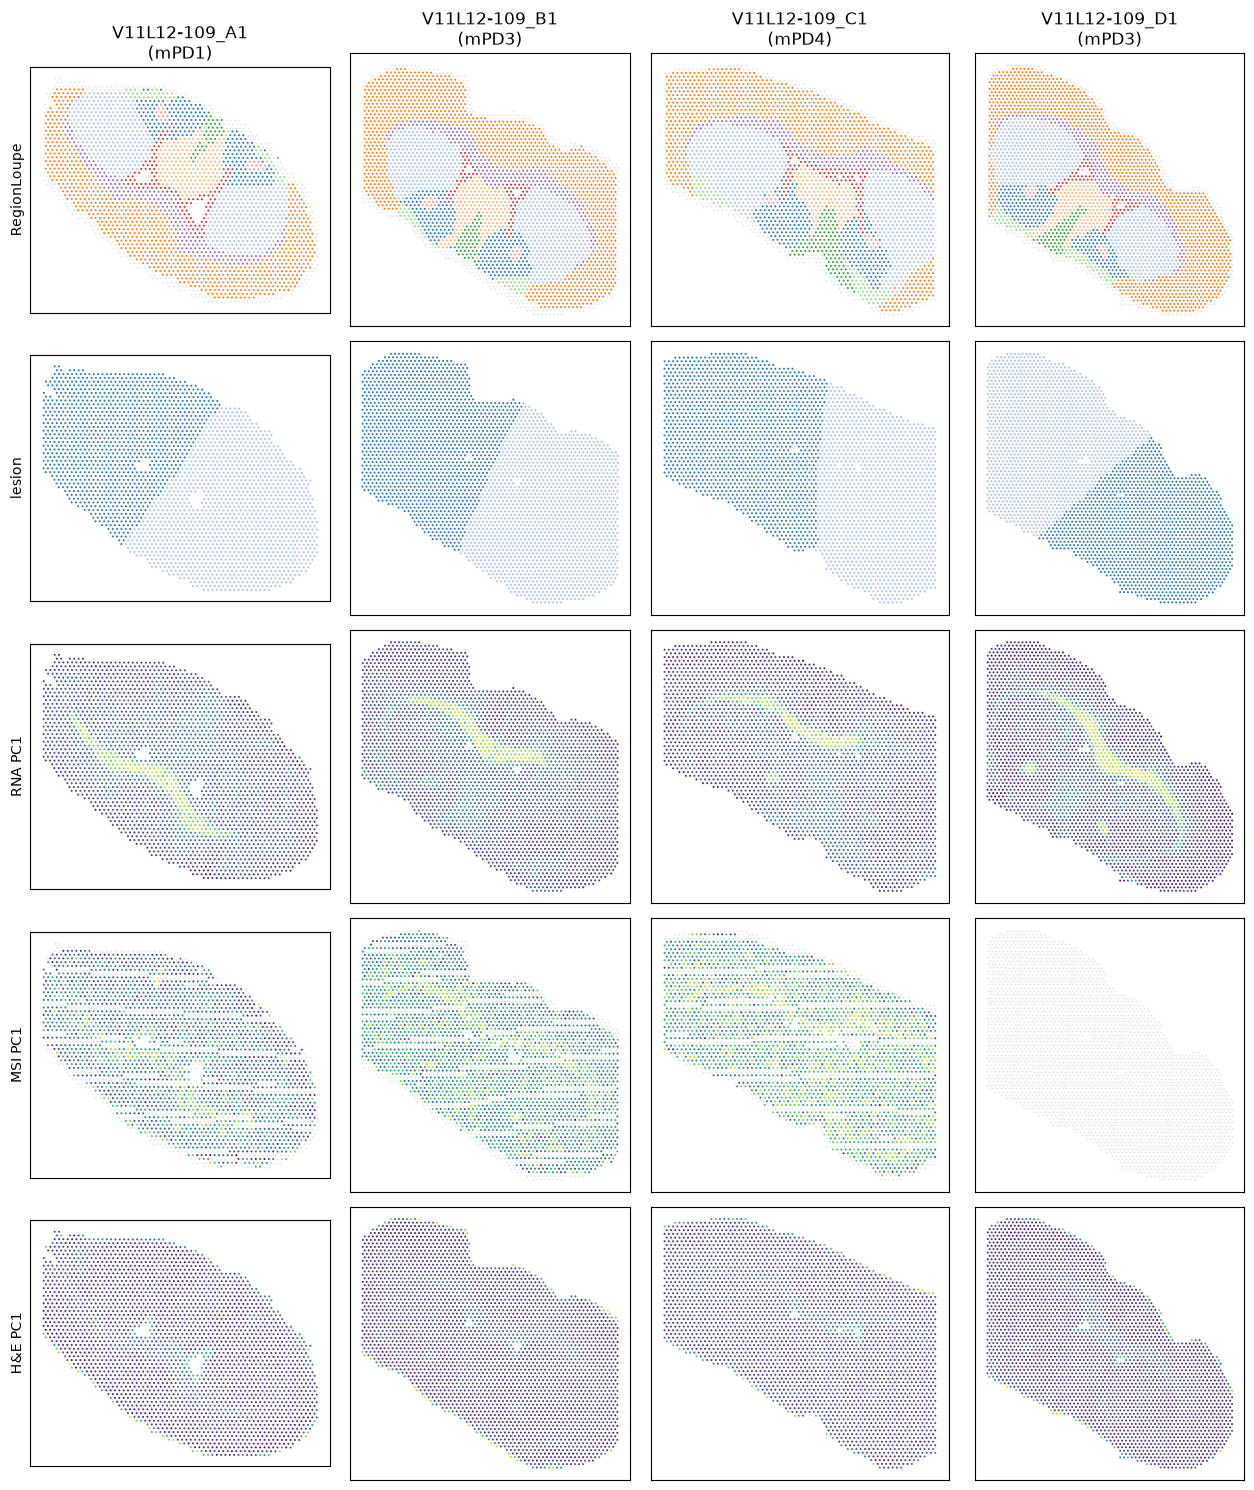

In [10]:
plot_cols = {
    "RegionLoupe": mdata.obs["RegionLoupe"],
    "lesion": mdata.obs["lesion"],
    "RNA PC1": pd.Series(rna.obsm["X_pca"][:, 0], index=rna.obs_names),
    "MSI PC1": pd.Series(msi.obsm["X_pca"][:, 0], index=msi.obs_names),
    "H&E PC1": pd.Series(he.obsm["X_pca"][:, 0], index=he.obs_names),
}
sections = list(SECTIONS)
fig, axes = plt.subplots(len(plot_cols), len(sections), figsize=(3.2 * len(sections), 3 * len(plot_cols)))
xy = pd.DataFrame(mdata.obsm["spatial"], index=mdata.obs_names, columns=["x", "y"])

for row, (label, values) in enumerate(plot_cols.items()):
    for col, section in enumerate(sections):
        ax = axes[row, col]
        spots = mdata.obs_names[mdata.obs["section"] == section]
        vals = values.reindex(spots)
        ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=2, c="#e5e5e5", linewidth=0)
        shown = vals.dropna().index
        if isinstance(vals.dtype, pd.CategoricalDtype):
            codes = vals[shown].cat.codes
            ax.scatter(xy.loc[shown, "x"], xy.loc[shown, "y"], s=2, c=codes, cmap="tab20", vmin=0, vmax=19, linewidth=0)
        else:
            ax.scatter(xy.loc[shown, "x"], xy.loc[shown, "y"], s=2, c=vals[shown], cmap="viridis", linewidth=0)
        ax.set(aspect=1, xticks=[], yticks=[])
        ax.invert_yaxis()
        if row == 0:
            ax.set_title(f"{section}\n({mdata.obs.loc[spots, 'mouse'].iloc[0]})")
        if col == 0:
            ax.set_ylabel(label)
fig.tight_layout()
plt.show()

## Section metadata and RNA batch effect (Harmony)

`metadata.csv` from the original study lists mouse and MALDI status per section (`Laser = nL`: no MALDI, D1 is the MALDI-free control on the same slide). The RNA UMAP coloured by section shows whether sections separate (batch effect, e.g. D1 without MALDI processing). Harmony (`harmonypy`, computed in the preprocessing cell) corrects the RNA PCs for `section` and stores them in `rna.obsm["X_pca_harmony"]`. `rna_rep` in the configuration decides which embedding all RNA-based graphs use (kNN graph, smoothed RNA, imputation source). *Same-section neighbours* is the fraction of each spot's 15 RNA neighbours in its own section, compared with the fraction expected if sections were fully mixed.

,mouse,Condition,Matrix,MALDI laser,Protocol,Brain.area,n_spots
Sample.ID,,,,,,,
V11L12-109_A1,mPD1,mPD,FMP-10,yL,Sma,Striatum,2675
V11L12-109_B1,mPD3,mPD,FMP-10,yL,Sma,Striatum,3120
V11L12-109_C1,mPD4,mPD,FMP-10,yL,Sma,Striatum,2918
V11L12-109_D1,mPD3,mPD,FMP-10,nL,Visium_iCtrl,Striatum,3017


,before Harmony,after Harmony,expected if mixed
same-section neighbours,,,
V11L12-109_A1,0.315,0.228,0.228
V11L12-109_B1,0.333,0.231,0.266
V11L12-109_C1,0.437,0.290,0.249
V11L12-109_D1,0.645,0.540,0.257


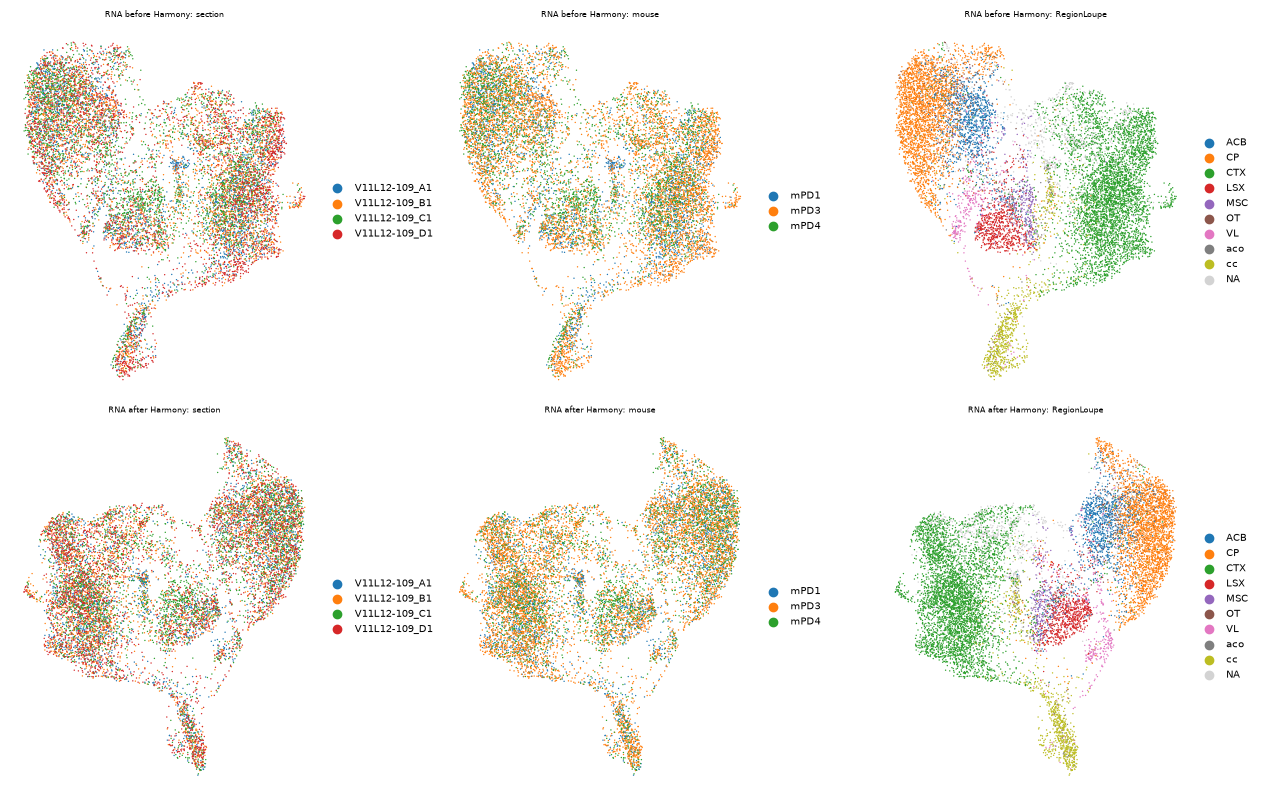

In [36]:
# section metadata of the original study (one row per Visium RNA library)
meta = pd.read_csv(data_dir / "metadata.csv")
meta = (meta[(meta["ArrayID"] == "V11L12-109") & (meta["Data.Type"] == "RNA")]
        .set_index("Sample.ID")[["sample", "Condition", "Matrix", "Laser", "Protocol", "Brain.area"]]
        .rename(columns={"sample": "mouse", "Laser": "MALDI laser"}))
meta["n_spots"] = rna.obs["section"].value_counts().reindex(meta.index)
display(meta)


def same_section_fraction(rep):
    tmp = ad.AnnData(obs=rna.obs[["section"]].copy(), obsm={rep: rna.obsm[rep]})
    sc.pp.neighbors(tmp, n_neighbors=n_neighbors, use_rep=rep, random_state=seed)
    sc.tl.umap(tmp, random_state=seed)
    g = tmp.obsp["distances"].tocoo()
    sec = tmp.obs["section"].to_numpy()
    same = pd.Series(sec[g.row] == sec[g.col]).groupby(sec[g.row]).mean()
    return tmp, same


umaps, mixing = {}, {}
for label, rep in {"before Harmony": "X_pca", "after Harmony": "X_pca_harmony"}.items():
    umaps[label], mixing[label] = same_section_fraction(rep)
mixing = pd.DataFrame(mixing)
mixing["expected if mixed"] = rna.obs["section"].value_counts(normalize=True)
display(mixing.round(3).rename_axis("same-section neighbours"))

colour_by = ["section", "mouse", "RegionLoupe"]
fig, axes = plt.subplots(2, len(colour_by), figsize=(4.2 * len(colour_by), 8))
for row, (label, tmp) in enumerate(umaps.items()):
    tmp.obs[colour_by] = rna.obs[colour_by]
    for col, key in enumerate(colour_by):
        sc.pl.umap(tmp, color=key, ax=axes[row, col], show=False, size=4, frameon=False,
                   title=f"RNA {label}: {key}", legend_fontsize=7)
fig.tight_layout()
fig.savefig(out_dir / "rna_umap_harmony.png", dpi=200)
plt.show()

# Save

In [11]:
mdata.write(out_file)
print("written:", out_file)

written: ../results/Cosie_Clustering/mouse_brain_6OHDA.h5mu


# SpatialLeiden: RNA, MSI, RNA + MSI and RNA + smoothed RNA

Each run combines one or both modality graphs with the spatial graph (`multiplex_leiden`, same resolution and layer weights for all runs). All spots of the sections with MALDI (A1–C1) are clustered: the ~18 % of spots without an MSI value have no edges in the MSI layer and get their label through the spatial (and RNA) layer, as in mosaic clustering. Scores are computed only on spots with MSI, so the three runs are compared on measured spots. Cluster colours are assigned per run and are not comparable between columns.

**RNA + smoothed RNA** is a control without any MSI: a second RNA layer built from the RNA PCs averaged over every spot and two rings of spatial neighbours (next cell). It tests how much of the lesion separation that MSI gives can already be obtained from spatially smoothed RNA.

In [37]:
# smoothed RNA layer (no MSI): RNA PCs averaged over every spot and n_rings_smooth rings of spatial neighbours,
# then a kNN graph. Same smoothing as in impute_modality_graph further below. The spatial graph has no edges
# between sections, so the averaging stays within a section.
n_rings_smooth = 2
smoother = sp.identity(mdata.n_obs) + (mdata.obsp["spatial_connectivities"] > 0).astype(float)
smoother = sp.diags(1 / np.asarray(smoother.sum(axis=1)).ravel()) @ smoother
X_smooth = pd.DataFrame(mdata.mod["rna"].obsm[rna_rep], index=mdata.mod["rna"].obs_names).loc[mdata.obs_names].to_numpy()
for _ in range(n_rings_smooth):
    X_smooth = smoother @ X_smooth
smoothed = ad.AnnData(obs=pd.DataFrame(index=mdata.obs_names), obsm={"X_smoothed": StandardScaler().fit_transform(X_smooth)})
sc.pp.neighbors(smoothed, n_neighbors=n_neighbors, use_rep="X_smoothed", random_state=seed)
mdata.obsp["rna_smoothed_connectivities"] = smoothed.obsp["connectivities"]
print("smoothed RNA graph:", mdata.obsp["rna_smoothed_connectivities"].shape)

smoothed RNA graph: (11730, 11730)


In [38]:
# run -> layer -> (resolution, layer weight); tune each run separately, e.g. to get the same number of clusters
# the spatial layer is weighted 0.5 by default, so that it smooths the clusters without dominating them
RUNS = {
    "RNA": {
        "rna": (1.0, 1.0),
        "spatial": (1.0, 0.5),
    },
    "MSI": {
        "msi": (1.0, 1.0),
        "spatial": (1.0, 0.5),
    },
    "RNA + MSI": {
        "rna": (1.0, 1.0),
        "msi": (1.0, 1.0),
        "spatial": (1.0, 0.5),
    },
    "RNA + smoothed RNA": {  # control without MSI: does the smoothed RNA alone separate the lesion?
        "rna": (1.0, 1.0),
        "rna_smoothed": (1.0, 1.0),
        "spatial": (1.0, 0.5),
    },
    "RNA + MSI + smoothed RNA": {
        "rna": (1.0, 1.0),
        "msi": (1.0, 1.0),
        "rna_smoothed": (1.0, 1.0),
        "spatial": (1.0, 0.5),
    },
}
sl_kwargs = {"directed": False, "n_iterations": 5, "random_state": seed}

# all spots of the sections with MALDI; spots without an MSI value have no edges in the MSI layer
# and get their label through the spatial (and RNA) layer
keep = mdata.obs["section"].isin(msi_sections).to_numpy()
sub_obs = mdata.obs[keep]
graphs = {name: mdata.obsp[f"{name}_connectivities"][keep][:, keep] for name in ["rna", "msi", "spatial", "rna_smoothed"]}

# scores only on spots that have MSI, so the three runs are compared on measured spots
annotated = sub_obs["has_msi"] & sub_obs["RegionLoupe"].notna() & sub_obs["lesion"].notna()
# the 6-OHDA lesion mainly affects the striatum (CP), so the lesion is also scored within CP only
annotated_cp = annotated & (sub_obs["RegionLoupe"] == "CP")


def run_spatialleiden(params):
    return multiplex_leiden(
        *[graphs[layer] for layer in params],
        partition_kwargs=[{"resolution_parameter": res} for res, _ in params.values()],
        layer_weights=[weight for _, weight in params.values()],
        **sl_kwargs,
    )


def score_runs(runs, labels):
    return pd.DataFrame({
        run: {
            "n_clusters": labels[run].nunique(),
            "ARI RegionLoupe": adjusted_rand_score(sub_obs.loc[annotated, "RegionLoupe"], labels.loc[annotated, run]),
            "ARI lesion": adjusted_rand_score(sub_obs.loc[annotated, "lesion"], labels.loc[annotated, run]),
            "ARI lesion in CP": adjusted_rand_score(sub_obs.loc[annotated_cp, "lesion"], labels.loc[annotated_cp, run]),
            "parameters": ", ".join(f"{layer} r={res:g} w={weight:g}" for layer, (res, weight) in params.items()),
        }
        for run, params in runs.items()
    }).T


sl_labels = pd.DataFrame({run: run_spatialleiden(p) for run, p in RUNS.items()}, index=sub_obs.index).astype("category")
sl_scores = score_runs(RUNS, sl_labels)
sl_scores

,n_clusters,ARI RegionLoupe,ARI lesion,ARI lesion in CP,parameters
RNA,8,0.581699,0.004116,0.000922,"rna r=1 w=1, spatial r=1 w=0.5"
MSI,11,0.12308,0.09016,0.579398,"msi r=1 w=1, spatial r=1 w=0.5"
RNA + MSI,8,0.532422,0.010118,0.023578,"rna r=1 w=1, msi r=1 w=1, spatial r=1 w=0.5"
RNA + smoothed RNA,11,0.391077,0.092663,0.924665,"rna r=1 w=1, rna_smoothed r=1 w=1, spatial r=1..."
RNA + MSI + smoothed RNA,10,0.353922,0.095619,0.757473,"rna r=1 w=1, msi r=1 w=1, rna_smoothed r=1 w=1..."


## Same number of clusters for every run

ARI depends on the number of clusters, so for a fair comparison all runs are brought to `n_clusters_target` (default: the 9 annotated regions + 1, because the lesioned CP is expected as its own domain). For every combination of layer weights (modality layers from `weight_grid`, the spatial layer from the lower `spatial_weight_grid`), one resolution shared by all layers is bisected until the run has exactly that many clusters; among the combinations that reach it, the one with the highest ARI against `select_by` is kept (default: regions with only CP split by lesion side, since the 6-OHDA lesion acts mainly on the striatum), written to `RUNS` and reclustered. All tested combinations are written to `spatialleiden_<n>_clusters_<select_by>.csv`. Parameters chosen with the annotation are an upper bound on what each modality can achieve, not an unbiased estimate.

In [39]:
n_clusters_target = 21 #sub_obs.loc[annotated, "RegionLoupe"].nunique() + 1  # 9 regions + lesioned CP as its own domain
# ARI that decides between weight combinations: "RegionLoupe", "lesion" (whole hemisphere), "region+lesion"
# (every region split by side) or "region+CP lesion" (regions, only CP split by side, where the lesion acts)
select_by = "region+CP lesion"
weight_grid = [0.5, 1.0, 2.0]  # weights of further modality layers, relative to the first layer of a run
spatial_weight_grid = [0.25, 0.5]  # spatial layer kept weaker; add 1.0 if MSI-only runs become too noisy


def resolution_for(weights, n_target, lo=0.01, hi=5.0, max_iter=15):
    # bisect one resolution shared by all layers until the clustering has n_target clusters
    for _ in range(max_iter):
        mid = (lo + hi) / 2
        labels = run_spatialleiden({layer: (mid, w) for layer, w in weights.items()})
        n = len(np.unique(labels))
        if n == n_target:
            return mid
        lo, hi = (mid, hi) if n < n_target else (lo, mid)
    return None


if select_by == "region+lesion":
    truth = sub_obs["RegionLoupe"].astype(str) + "_" + sub_obs["lesion"].astype(str)
elif select_by == "region+CP lesion":
    region = sub_obs["RegionLoupe"].astype(str)
    truth = region.where(region != "CP", "CP_" + sub_obs["lesion"].astype(str))
else:
    truth = sub_obs[select_by]
truth = truth[annotated].to_numpy()

records = []
for run, params in RUNS.items():
    layers = [layer for layer in params if layer != "spatial"]
    for modality_weights, w_spatial in itertools.product(
        itertools.product(weight_grid, repeat=len(layers) - 1), spatial_weight_grid
    ):
        weights = {**dict(zip(layers, (1.0, *modality_weights))), "spatial": w_spatial}
        res = resolution_for(weights, n_clusters_target)
        if res is None:
            continue
        labels = run_spatialleiden({layer: (res, w) for layer, w in weights.items()})
        records.append({
            "run": run,
            "resolution": res,
            **{f"w_{layer}": w for layer, w in weights.items()},
            "ARI": adjusted_rand_score(truth, labels[annotated.to_numpy()]),
        })
fixed_k = pd.DataFrame(records)
fixed_k.to_csv(out_dir / f"spatialleiden_{n_clusters_target}_clusters_{select_by}.csv", index=False)
missing = set(RUNS) - set(fixed_k["run"])
assert not missing, f"no parameters found that give {n_clusters_target} clusters for {missing}"
best = fixed_k.loc[fixed_k.groupby("run", sort=False)["ARI"].idxmax()].set_index("run")

# take over the best parameters and recluster with them
RUNS = {
    run: {layer: (float(best.loc[run, "resolution"]), float(best.loc[run, f"w_{layer}"])) for layer in params}
    for run, params in RUNS.items()
}
sl_labels = pd.DataFrame({run: run_spatialleiden(p) for run, p in RUNS.items()}, index=sub_obs.index).astype("category")
sl_scores = score_runs(RUNS, sl_labels)
sl_scores

,n_clusters,ARI RegionLoupe,ARI lesion,ARI lesion in CP,parameters
RNA,21,0.261176,0.005011,0.03254,"rna r=2.42703 w=1, spatial r=2.42703 w=0.5"
MSI,21,0.076159,0.044654,0.30472,"msi r=1.55963 w=1, spatial r=1.55963 w=0.25"
RNA + MSI,21,0.257823,0.024173,0.256759,"rna r=2.19312 w=1, msi r=2.19312 w=0.5, spatia..."
RNA + smoothed RNA,21,0.229278,0.038844,0.357534,"rna r=1.82277 w=1, rna_smoothed r=1.82277 w=0...."
RNA + MSI + smoothed RNA,21,0.267258,0.051831,0.578665,"rna r=2.05668 w=1, msi r=2.05668 w=0.5, rna_sm..."


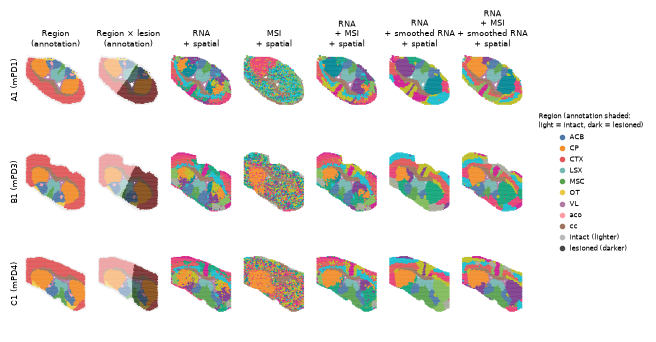

In [40]:
# Clusters of RNA, MSI and RNA + MSI (each with the spatial graph) next to the annotation, to be compared by eye.
# Every cluster gets the colour of the region it overlaps most; if several clusters share a region, the largest
# keeps the region colour and the others get own colours. Only the region x lesion annotation is shaded.
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 6,
    "axes.titlesize": 6, "legend.fontsize": 5, "pdf.fonttype": 42, "svg.fonttype": "none",
})
REGION_COLORS = ["#4E79A7", "#F28E2B", "#E15759", "#76B7B2", "#59A14F", "#EDC948", "#B07AA1", "#FF9DA7", "#9C755F"]
EXTRA_COLORS = ["#17BECF", "#BCBD22", "#7F3C8D", "#11A579", "#E73F74", "#80BA5A", "#008695", "#CF1C90", "#A5AA99"]
regions = sorted(mdata.obs["RegionLoupe"].dropna().astype(str).unique())
region_color = dict(zip(regions, REGION_COLORS))


def shade(color, lesioned_fraction):
    # 0 = all intact (lighter), 0.5 = region colour, 1 = all lesioned (darker)
    rgb = np.array(to_rgb(color))
    a = (lesioned_fraction - 0.5) * 2 * 0.45
    return to_hex(rgb * (1 - a) if a > 0 else rgb + (1 - rgb) * -a)


def cluster_colors(labels, obs):
    # colour of every cluster: the region it overlaps most (no shading)
    ok = (obs["RegionLoupe"].notna() & obs["lesion"].notna()).to_numpy()
    df = pd.DataFrame({
        "cluster": labels[ok].to_numpy(),
        "region": obs.loc[ok, "RegionLoupe"].astype(str).to_numpy(),
        "lesioned": (obs.loc[ok, "lesion"].astype(str) == "lesioned").to_numpy(),
    })
    counts = pd.crosstab(df["cluster"], df["region"])
    region, size = counts.idxmax(axis=1), counts.max(axis=1)
    # the largest cluster of a region keeps the region colour, further clusters of that region get own colours
    colors, used, extra = {}, set(), itertools.cycle(EXTRA_COLORS)
    for c in size.sort_values(ascending=False).index:
        colors[c] = next(extra) if region[c] in used else region_color[region[c]]
        used.add(region[c])
    return colors


msi_section_names = [s for s in SECTIONS if s in msi_sections]
xy = pd.DataFrame(mdata.obsm["spatial"], index=mdata.obs_names, columns=["x", "y"])
colors_per_run = {run: cluster_colors(sl_labels[run], sub_obs) for run in RUNS}

mm = 1 / 25.4
n_maps = 2 + len(RUNS)
fig, axes = plt.subplots(
    len(msi_section_names), n_maps + 1, figsize=(183 * mm, 33 * mm * len(msi_section_names)),
    gridspec_kw={"width_ratios": [1] * n_maps + [0.75], "wspace": 0.12, "hspace": 0.06},
)
for row, section_name in enumerate(msi_section_names):
    spots = sub_obs.index[sub_obs["section"] == section_name]
    obs = sub_obs.loc[spots]
    region_here = obs["RegionLoupe"].astype(str)
    lesioned_here = (obs["lesion"].astype(str) == "lesioned").astype(float)
    panels = [
        ("Region\n(annotation)", [region_color.get(r, "#f0f0f0") for r in region_here]),
        ("Region × lesion\n(annotation)", [shade(region_color[r], l) if r in region_color else "#f0f0f0"
                                           for r, l in zip(region_here, lesioned_here)]),
    ] + [
        ("\n+ ".join(f"{run} + spatial".split(" + ")), [colors_per_run[run].get(c, "#bdbdbd") for c in sl_labels.loc[spots, run]])
        for run in RUNS
    ]
    for col, (title, colors) in enumerate(panels):
        ax = axes[row, col]
        ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=0.9, c=colors, linewidth=0, rasterized=True)
        ax.set_aspect(1)
        ax.invert_yaxis()
        ax.axis("off")
        if row == 0:
            ax.set_title(title, pad=3, va="bottom", fontsize=5.5)
    axes[row, 0].text(-0.06, 0.5, f"{section_name.split('_')[1]} ({obs['mouse'].iloc[0]})",
                      transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right")
    axes[row, -1].axis("off")

axes[len(msi_section_names) // 2, -1].legend(
    handles=[plt.Line2D([], [], marker="o", ls="", ms=3, color=region_color[r], label=r) for r in regions]
    + [plt.Line2D([], [], marker="o", ls="", ms=3, color=shade("#808080", f), label=l)
       for l, f in [("intact (lighter)", 0.0), ("lesioned (darker)", 1.0)]],
    loc="center left", frameon=False, handletextpad=0.1, title="Region (annotation shaded:\nlight = intact, dark = lesioned)", title_fontsize=5,
)
fig.savefig(out_dir / "spatialleiden_rna_msi.pdf", dpi=600, bbox_inches="tight")
fig.savefig(out_dir / "spatialleiden_rna_msi.png", dpi=300, bbox_inches="tight")
plt.show()

# Multisample / multimodal clustering without integration

All sections that a run can use are clustered **in one `multiplex_leiden` call**, so a cluster label means the same thing in every section. There is no batch correction: the RNA and MSI kNN graphs are built on one PCA over all sections (preprocessing above), and the spatial graph has no edges between sections. Each run uses only the sections in which all its modalities are measured: RNA on A1–D1, MSI and RNA + MSI on A1–C1. Parameters are taken from `RUNS` (default or tuned in the cell above).

- The first table shows how well the sections mix without integration: the share of kNN neighbours from the spot's own section, compared with the share expected under perfect mixing.
- Scores: ARI per section and pooled over all clustered sections (`all`), on all annotated spots (incl. spots without MSI). A pooled ARI below the per-section ARIs means the same cluster is used for different regions in different sections.

In [15]:
all_sections = list(SECTIONS)
msi_section_names = [s for s in SECTIONS if s in msi_sections]
score_spots = mdata.obs["RegionLoupe"].notna() & mdata.obs["lesion"].notna()
section_of = mdata.obs["section"].astype(str).to_numpy()


def neighbour_mixing(name):
    # share of a spot's kNN neighbours that come from its own section, and what it would be with perfect mixing
    graph = mdata.obsp[f"{name}_connectivities"]
    g = graph.tocoo()
    measured = np.asarray(graph.sum(axis=1)).ravel() > 0
    return pd.DataFrame({
        (name, "same section"): pd.Series(section_of[g.row] == section_of[g.col]).groupby(section_of[g.row]).mean(),
        (name, "if mixed"): pd.Series(section_of[measured]).value_counts(normalize=True),
    })


display(pd.concat([neighbour_mixing(name) for name in ["rna", "msi"]], axis=1).round(2))


def cluster_sections(params, sections):
    # one multiplex_leiden call over all spots of the given sections; returns one shared label per spot
    keep = mdata.obs["section"].isin(sections).to_numpy()
    labels = multiplex_leiden(
        *[mdata.obsp[f"{layer}_connectivities"][keep][:, keep] for layer in params],
        partition_kwargs=[{"resolution_parameter": res} for res, _ in params.values()],
        layer_weights=[weight for _, weight in params.values()],
        **sl_kwargs,
    )
    return pd.Series(labels, index=mdata.obs_names[keep]).astype("category")


def score_by_section(labels):
    # ARI per section and pooled over all clustered sections ("all"), on all annotated spots
    obs = mdata.obs.loc[labels.index].assign(cluster=labels)
    obs = obs[score_spots[labels.index]]
    groups = {"all": obs, **dict(list(obs.groupby(obs["section"].astype(str))))}
    return pd.DataFrame({
        name: {
            "n_clusters": g["cluster"].nunique(),
            "ARI region": adjusted_rand_score(g["RegionLoupe"], g["cluster"]),
            "ARI lesion": adjusted_rand_score(g["lesion"], g["cluster"]),
        }
        for name, g in groups.items()
    }).T


# run -> (layer parameters from RUNS above, sections); every run only on sections where all its modalities exist
JOINT_RUNS = {
    "RNA": (RUNS["RNA"], all_sections),
    "MSI": (RUNS["MSI"], msi_section_names),
    "RNA + MSI": (RUNS["RNA + MSI"], msi_section_names),
}
joint_labels = {run: cluster_sections(params, sections) for run, (params, sections) in JOINT_RUNS.items()}
joint_scores = pd.concat({run: score_by_section(labels) for run, labels in joint_labels.items()})
joint_scores.astype(float).unstack().round(2)

rna                   msi         
              same section if mixed same section if mixed
V11L12-109_A1         0.30     0.23         0.54     0.31
V11L12-109_B1         0.32     0.27         0.41     0.36
V11L12-109_C1         0.40     0.25         0.47     0.33
V11L12-109_D1         0.46     0.26          NaN      NaN

n_clusters                                                 \
          V11L12-109_A1 V11L12-109_B1 V11L12-109_C1 V11L12-109_D1  all   
RNA                 9.0           9.0           9.0           9.0  9.0   
MSI                 5.0           8.0           6.0           NaN  9.0   
RNA + MSI           9.0           9.0           9.0           NaN  9.0   

             ARI region                                                  \
          V11L12-109_A1 V11L12-109_B1 V11L12-109_C1 V11L12-109_D1   all   
RNA                0.61          0.47          0.46          0.46  0.49   
MSI                0.20          0.29          0.21           NaN  0.14   
RNA + MSI          0.47          0.42          0.42           NaN  0.42   

             ARI lesion                                                  
          V11L12-109_A1 V11L12-109_B1 V11L12-109_C1 V11L12-109_D1   all  
RNA                0.00          0.00          0.03          0.01  0.00  
MSI                0.17          0.21          0.24           NaN  0.14  
RNA + MSI          0.09          0.07          0.12           NaN  0.09

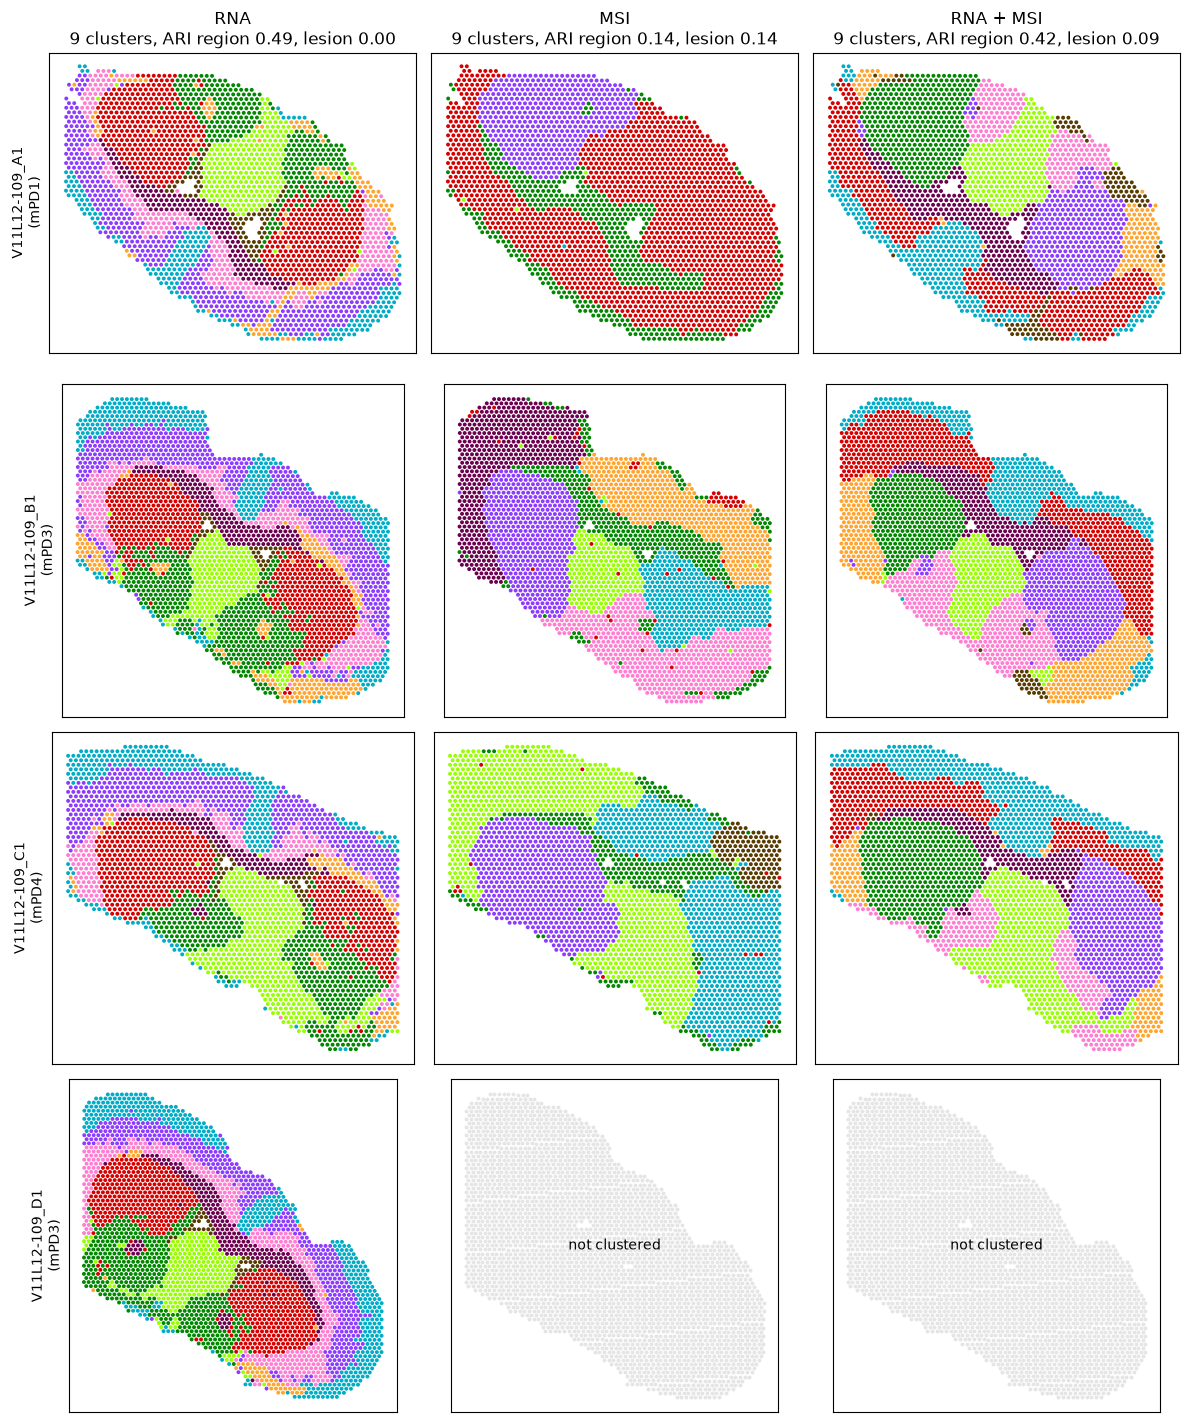

In [16]:
def plot_runs(labels, file_name):
    # rows = sections, columns = runs; colours are per run but shared across sections, so the same colour
    # in two sections of one column is the same cluster
    xy = pd.DataFrame(mdata.obsm["spatial"], index=mdata.obs_names, columns=["x", "y"])
    fig, axes = plt.subplots(
        len(all_sections), len(labels), figsize=(4 * len(labels), 3.6 * len(all_sections)), squeeze=False
    )
    for col, (run, lab) in enumerate(labels.items()):
        palette = dict(zip(lab.cat.categories, cc.glasbey))
        pooled = score_by_section(lab).loc["all"]
        for row, section in enumerate(all_sections):
            ax = axes[row, col]
            spots = mdata.obs_names[mdata.obs["section"] == section]
            shown = spots[spots.isin(lab.index)]
            if len(shown):
                ax.scatter(xy.loc[shown, "x"], xy.loc[shown, "y"], s=8, c=lab[shown].map(palette).tolist(),
                           linewidth=0, rasterized=True)
            else:
                ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=8, c="#e5e5e5", linewidth=0, rasterized=True)
                ax.text(0.5, 0.5, "not clustered", transform=ax.transAxes, ha="center", va="center")
            ax.set(aspect=1, xticks=[], yticks=[])
            ax.invert_yaxis()
            if row == 0:
                ax.set_title(f"{run}\n{pooled['n_clusters']:.0f} clusters, ARI region {pooled['ARI region']:.2f}, "
                             f"lesion {pooled['ARI lesion']:.2f}")
            if col == 0:
                ax.set_ylabel(f"{section}\n({mdata.obs.loc[spots, 'mouse'].iloc[0]})")
    fig.tight_layout()
    fig.savefig(file_name, dpi=300, bbox_inches="tight")
    plt.show()


plot_runs(joint_labels, out_dir / "spatialleiden_joint_no_integration.pdf")

# Mosaic clustering, first run

RNA + MSI + spatial on **all four sections**, D1 included although it has no MSI (the COSIE setting: Section 3 without MSI). D1 spots have no edges in the MSI layer and are connected to the other sections only through the RNA layer and to each other through the spatial layer. Compared with:
- **RNA (A1–D1)**: does D1 profit from the MSI measured in the other sections (mainly ARI lesion in D1)?
- **RNA + MSI (A1–C1)**: does adding a section without MSI hurt the sections with MSI?
- **all**: one ARI over all sections; high only if the same cluster means the same region in every section.

All runs are brought to `n_clusters_mosaic` clusters (shared resolution bisected), so the ARIs are comparable.

**Layer balance.** `multiplex_leiden` sums the modularity of the layers, and a layer's share grows with its total edge weight. Adding D1 doubles the RNA edges (and adds 35 % spatial edges) but no MSI edges, so with equal `layer_weights` RNA dominates and the lesion signal from MSI is lost. `normalize_layers = True` scales every layer by 1 / its total edge weight on the clustered sections, so each layer counts equally whatever number of sections it covers. Compare `True` and `False`, and check the section table: clusters that exist only in D1 or not in D1 mean the mosaic splits spots with and without MSI instead of sharing clusters.

RNA (A1–D1)                             r=1.102, rna w=0.90, spatial w=1.12
RNA + MSI (A1–C1)           r=1.102, rna w=1.10, msi w=0.99, spatial w=0.93
RNA + MSI mosaic (A1–D1)    r=0.946, rna w=0.79, msi w=1.40, spatial w=0.98


n_clusters                              \
                         V11L12-109_A1 V11L12-109_B1 V11L12-109_C1   
RNA (A1–D1)                        9.0           9.0           9.0   
RNA + MSI (A1–C1)                  9.0           9.0           9.0   
RNA + MSI mosaic (A1–D1)           9.0           9.0           9.0   

                                               ARI region                \
                         V11L12-109_D1  all V11L12-109_A1 V11L12-109_B1   
RNA (A1–D1)                        9.0  9.0          0.48          0.46   
RNA + MSI (A1–C1)                  NaN  9.0          0.51          0.43   
RNA + MSI mosaic (A1–D1)           9.0  9.0          0.31          0.32   

                                                              ARI lesion  \
                         V11L12-109_C1 V11L12-109_D1   all V11L12-109_A1   
RNA (A1–D1)                       0.57          0.46  0.47          0.01   
RNA + MSI (A1–C1)                 0.45           NaN  0.45          0.09   
RNA + MSI mosaic (A1–D1)          0.30          0.59  0.25          0.18   

                                                                          
                         V11L12-109_B1 V11L12-109_C1 V11L12-109_D1   all  
RNA (A1–D1)                       0.01          0.03          0.01  0.01  
RNA + MSI (A1–C1)                 0.08          0.12           NaN  0.09  
RNA + MSI mosaic (A1–D1)          0.10          0.12          0.01  0.06

section,V11L12-109_A1,V11L12-109_B1,V11L12-109_C1,V11L12-109_D1
row_0,,,,
0,69,886,1236,86
1,1374,581,236,47
2,482,465,579,639
3,552,480,408,398
4,15,28,34,967
5,8,397,338,96
6,9,107,22,397
7,159,125,64,159
8,7,51,1,228


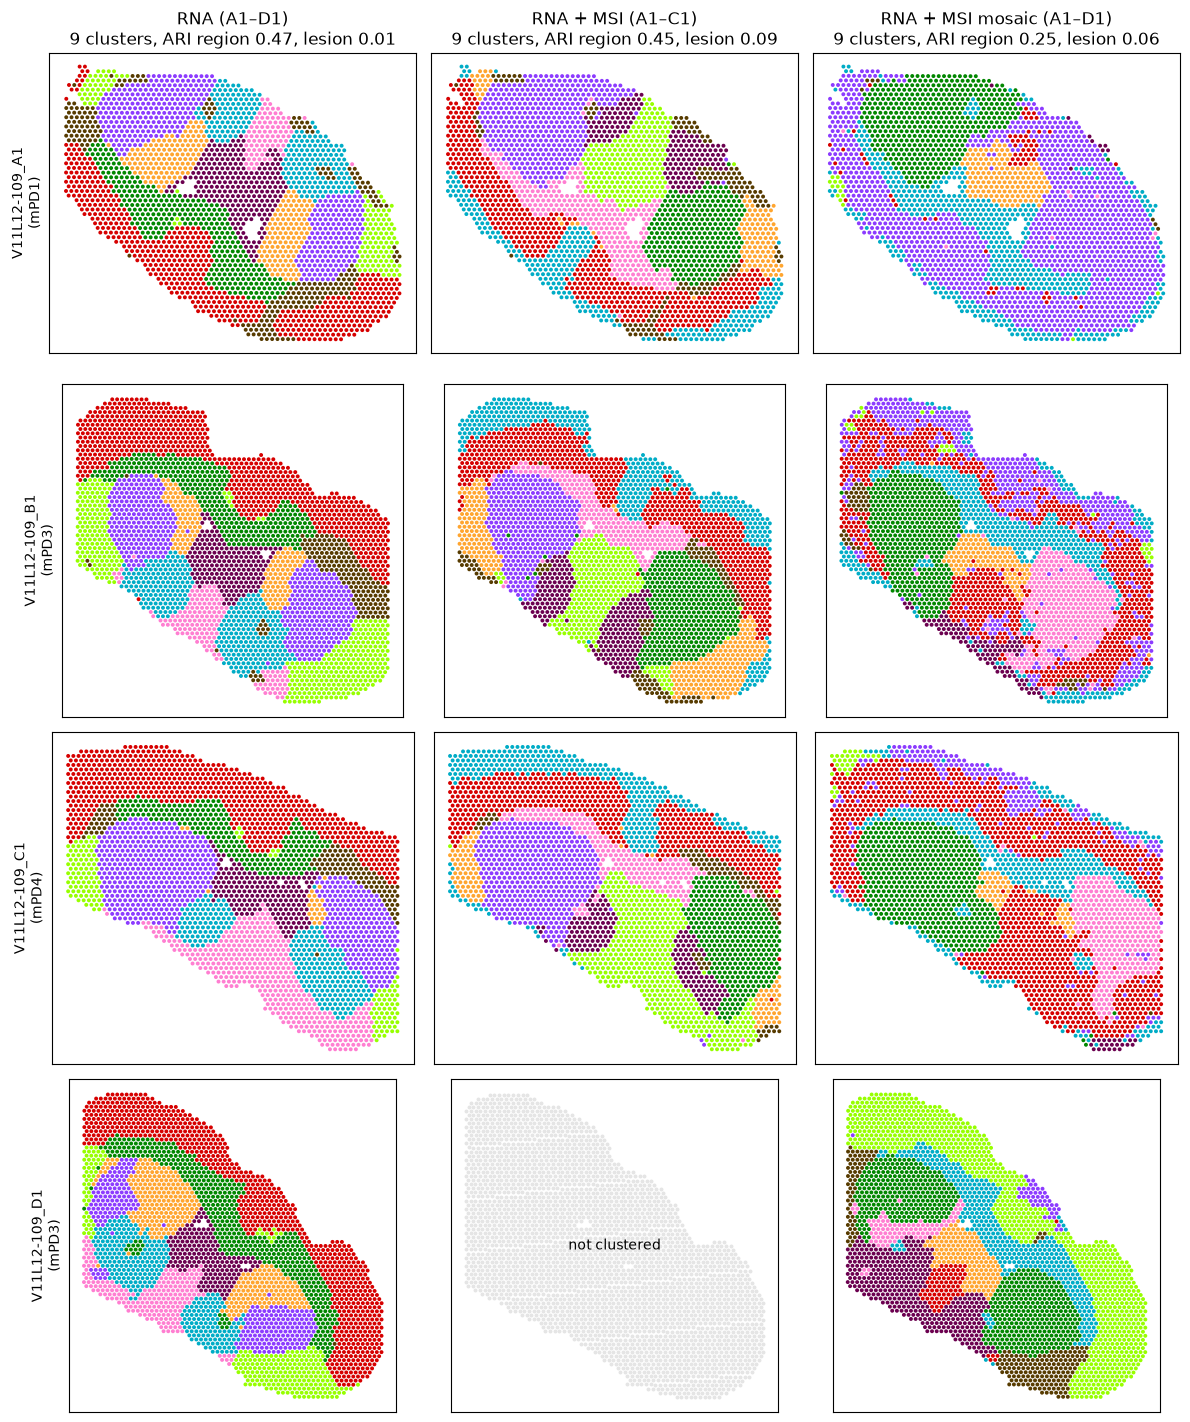

In [36]:
n_clusters_mosaic = 9  # same number of clusters for every run, e.g. the 9 annotated regions
normalize_layers = True  # scale each layer by 1 / its total edge weight on the clustered sections

# run -> (layer -> weight before normalisation, sections); one resolution shared by all layers is bisected per run
MOSAIC_RUNS = {
    "RNA (A1–D1)": ({"rna": 1.0, "spatial": 1.0}, all_sections),
    "RNA + MSI (A1–C1)": ({"rna": 1.0, "msi": 1.0, "spatial": 1.0}, msi_section_names),
    "RNA + MSI mosaic (A1–D1)": ({"rna": 1.0, "msi": 1.0, "spatial": 1.0}, all_sections),
}


def effective_weights(weights, sections):
    # a layer's share of the multiplex modularity grows with its total edge weight; a layer that is
    # measured on more sections (RNA, spatial) would otherwise dominate one missing in a section (MSI)
    if not normalize_layers:
        return dict(weights)
    keep = mdata.obs["section"].isin(sections).to_numpy()
    totals = {layer: mdata.obsp[f"{layer}_connectivities"][keep][:, keep].sum() for layer in weights}
    mean_total = np.mean(list(totals.values()))
    return {layer: w * mean_total / totals[layer] for layer, w in weights.items()}


def cluster_at_k(weights, sections, n_target, lo=0.01, hi=5.0, max_iter=20):
    # bisect one resolution shared by all layers until the clustering has n_target clusters
    for _ in range(max_iter):
        res = (lo + hi) / 2
        labels = cluster_sections({layer: (res, w) for layer, w in weights.items()}, sections)
        if labels.nunique() == n_target:
            return labels, res
        lo, hi = (res, hi) if labels.nunique() < n_target else (lo, res)
    raise ValueError(f"no resolution gives {n_target} clusters for weights {weights}")


mosaic_compare, mosaic_params = {}, {}
for run, (weights, sections) in MOSAIC_RUNS.items():
    w = effective_weights(weights, sections)
    mosaic_compare[run], res = cluster_at_k(w, sections, n_clusters_mosaic)
    mosaic_params[run] = f"r={res:.3f}, " + ", ".join(f"{layer} w={v:.2f}" for layer, v in w.items())
mosaic_labels = mosaic_compare["RNA + MSI mosaic (A1–D1)"]

print(pd.Series(mosaic_params).to_string())
mosaic_scores = pd.concat({run: score_by_section(labels) for run, labels in mosaic_compare.items()})
display(mosaic_scores.astype(float).unstack().round(2))

# spots of each mosaic cluster per section: clusters (almost) only in D1 or (almost) absent from D1 mean that
# the mosaic separates spots with and without MSI instead of sharing clusters across sections
display(pd.crosstab(mosaic_labels, mdata.obs.loc[mosaic_labels.index, "section"]))

plot_runs(mosaic_compare, out_dir / f"spatialleiden_mosaic_k{n_clusters_mosaic}{'_normalized' if normalize_layers else ''}.pdf")

# Mosaic clustering with imputed edges for the missing modality

`impute_modality_graph` gives spots without a modality edges in that modality's layer instead of leaving them isolated. A ridge regression learns, on the spots where both are measured, to predict the MSI embedding (PCs) from the RNA embedding averaged over the spot and its spatial neighbours (`n_rings=2`; spatial averaging raised the lesion signal in the predicted MSI from AUC ~0.62 to ~0.80 in a leave-one-section-out test). Unmeasured spots get kNN edges in the predicted space, where measured spots are represented by out-of-fold predictions so both are compared on equal terms. Measured–measured edges are the usual kNN graph on the measured MSI. `imputed_weight=0` gives the plain mosaic with isolated nodes.

`cluster_mosaic` scales every layer by 1 / its total edge weight (a layer measured on fewer sections would otherwise count less) and bisects one shared resolution to a fixed number of clusters. Nothing here uses the annotation.

In [17]:
def impute_modality_graph(mdata, target, measured, source="rna", spatial_key="spatial_connectivities",
                          n_rings=2, n_neighbors=15, imputed_weight=1.0, group_key="section", predict=True, n_target_pcs=30, source_rep="X_pca", seed=0):
    """kNN graph of modality `target` on all spots of `mdata`, including spots where it was not measured.

    measured spots: kNN graph on a PCA of `mdata[target].X` (n_target_pcs components) that is fitted on the
    measured spots only, so masked or unmeasured spots never influence the target embedding.
    unmeasured spots: the `target` embedding is predicted from the `source` embedding (`source_rep`, e.g. X_pca or X_pca_harmony), averaged
    over `n_rings` rings of spatial neighbours, with a ridge regression trained on the measured spots.
    Their edges come from a kNN graph in the predicted space, in which measured spots are represented
    by out-of-fold predictions (leave one `group_key` out), so that measured and unmeasured spots are
    compared on equal terms. These edges are multiplied by `imputed_weight` (0 = isolated nodes).
    predict=False is a control: the edges of unmeasured spots come directly from the smoothed source
    embedding, without predicting the target modality.

    Returns the graph (spots x spots, order of mdata.obs_names) and a dict with the out-of-fold R2.
    """
    obs_names = mdata.obs_names
    measured = np.asarray(measured, dtype=bool)
    n = len(obs_names)

    # source embedding, averaged over the spot and its spatial neighbours (n_rings times)
    X = pd.DataFrame(mdata[source].obsm[source_rep], index=mdata[source].obs_names).reindex(obs_names).to_numpy()
    assert not np.isnan(X).any(), f"every spot needs the source modality '{source}'"
    smoother = sp.identity(n) + (mdata.obsp[spatial_key] > 0).astype(float)
    smoother = sp.diags(1 / np.asarray(smoother.sum(axis=1)).ravel()) @ smoother
    for _ in range(n_rings):
        X = smoother @ X
    X = StandardScaler().fit_transform(X)

    # target embedding of the measured spots (PCA fitted on them only)
    T = mdata[target][obs_names[measured]].X
    T = T.toarray() if sp.issparse(T) else np.asarray(T)
    Y = PCA(n_components=n_target_pcs, random_state=seed).fit_transform(T)
    groups = mdata.obs[group_key].astype(str).to_numpy()[measured]
    n_groups = len(np.unique(groups))
    model = RidgeCV(alphas=np.logspace(-1, 4, 11))
    if n_groups > 1:
        Y_oof = cross_val_predict(model, X[measured], Y, groups=groups, cv=GroupKFold(n_splits=n_groups))
    else:
        Y_oof = cross_val_predict(model, X[measured], Y, cv=5)
    model.fit(X[measured], Y)
    if predict:
        Z = np.empty((n, Y.shape[1]))
        Z[measured] = Y_oof
        Z[~measured] = model.predict(X[~measured])
    else:
        Z = X

    def knn(emb):
        a = ad.AnnData(obs=pd.DataFrame(index=np.arange(len(emb)).astype(str)), obsm={"emb": emb})
        sc.pp.neighbors(a, n_neighbors=n_neighbors, use_rep="emb", random_state=seed)
        return a.obsp["connectivities"].tocoo()

    # measured - measured: graph on the measured embedding
    idx = np.flatnonzero(measured)
    g = knn(Y)
    graph = sp.csr_matrix((g.data, (idx[g.row], idx[g.col])), shape=(n, n))

    # edges that involve an unmeasured spot: graph on the predicted embedding
    if imputed_weight > 0 and (~measured).any():
        g = knn(Z)
        keep = ~measured[g.row] | ~measured[g.col]
        graph = graph + sp.csr_matrix((imputed_weight * g.data[keep], (g.row[keep], g.col[keep])), shape=(n, n))

    info = {"r2_out_of_fold": r2_score(Y, Y_oof, multioutput="variance_weighted"), "ridge_alpha": model.alpha_,
            "n_measured": int(measured.sum()), "n_imputed": int((~measured).sum()) if imputed_weight > 0 else 0}
    return graph.tocsr(), info


def cluster_mosaic(graphs, n_clusters, seed, lo=0.01, hi=5.0, max_iter=25):
    """multiplex_leiden on {layer: graph}; every layer is scaled by 1 / its total edge weight, and one
    resolution shared by all layers is bisected until there are `n_clusters` clusters."""
    totals = np.array([g.sum() for g in graphs.values()])
    weights = list(totals.mean() / totals)
    for _ in range(max_iter):
        res = (lo + hi) / 2
        labels = multiplex_leiden(
            *graphs.values(), partition_kwargs=[{"resolution_parameter": res}] * len(graphs),
            layer_weights=weights, directed=False, n_iterations=5, random_state=seed,
        )
        n = len(np.unique(labels))
        if n == n_clusters:
            break
        lo, hi = (res, hi) if n < n_clusters else (lo, res)
    return labels

## Validation

**Experiment 1 – masking (A1–C1).** The MSI of `masked_section` (B1, same mouse as D1) is hidden, so the result can be compared with the clustering on the real MSI. **Experiment 2 – mosaic (A1–D1).** D1 has no MSI.

Methods (always three layers: RNA, an MSI layer, spatial; they differ only in the MSI layer):
- *RNA only*: no MSI layer (lower bound). *Full MSI* (experiment 1): real MSI of B1 (reference).
- *isolated*: spots without MSI have no MSI edges (plain mosaic).
- *imputed*: `impute_modality_graph`, MSI predicted from RNA smoothed over 2 rings.
- control *RNA edges*: as imputed, but the edges of spots without MSI come directly from the smoothed RNA (`predict=False`) — tests whether predicting MSI adds anything beyond the smoothing.
- control *imputed, no smoothing*: as imputed with `n_rings=0` — tests how much depends on the smoothing.

In both experiments the ~18 % of A1–C1 spots without MSI are treated like the masked section. All methods have `n_clusters_exp` clusters; ARI per section and pooled over sections (`all`; high only if a cluster means the same region in every section). Scores go to `mosaic_imputation_scores.csv`. Runtime ~5 min per seed.

Result with 5 seeds (mean ARI lesion, B1 masked / D1): full MSI 0.088 / –, isolated 0.010 / 0.015, imputed 0.075 / 0.041, RNA edges 0.066 / 0.045, no smoothing 0.005 / 0.009. The gain comes mainly from the spatial smoothing; predicting MSI adds little on top (B1 +0.009, D1 none) but keeps clusters more consistent across sections (pooled ARI region 0.441 vs 0.407 in the mosaic).

In [18]:
n_clusters_exp = 9  # number of clusters for every method (9 annotated regions)
exp_seeds = range(1)  # Leiden seeds (~5 min per seed); use range(5) for the final figure
masked_section = "V11L12-109_B1"  # MSI section whose MSI is hidden in experiment 1 (same mouse as D1)

section = mdata.obs["section"].astype(str)
has_msi = mdata.obs["has_msi"].to_numpy()
known = mdata.obs["RegionLoupe"].notna() & mdata.obs["lesion"].notna()

# MSI graphs: measured spots only (isolated nodes elsewhere) or with imputed edges for the other spots
msi_graphs, imputation_info = {}, {}
masked = has_msi & (section != masked_section).to_numpy()
# name -> (measured spots, keyword arguments); the last two of each block are controls:
# "RNA edges" = edges of unmeasured spots from the smoothed RNA itself (no MSI prediction),
# "no smoothing" = MSI predicted from the RNA of the spot alone (n_rings=0)
GRAPH_SETTINGS = {
    "msi isolated": (has_msi, {"imputed_weight": 0.0}),
    "msi imputed": (has_msi, {}),
    "msi RNA edges": (has_msi, {"predict": False}),
    "msi imputed, no smoothing": (has_msi, {"n_rings": 0}),
    "msi masked, isolated": (masked, {"imputed_weight": 0.0}),
    "msi masked, imputed": (masked, {}),
    "msi masked, RNA edges": (masked, {"predict": False}),
    "msi masked, imputed, no smoothing": (masked, {"n_rings": 0}),
}
for name, (measured, kwargs) in GRAPH_SETTINGS.items():
    msi_graphs[name], imputation_info[name] = impute_modality_graph(mdata, "msi", measured, source_rep=rna_rep, seed=seed, **kwargs)
display(pd.DataFrame(imputation_info).T)

layer_graphs = {"rna": mdata.obsp["rna_connectivities"], "spatial": mdata.obsp["spatial_connectivities"], **msi_graphs}

# experiment -> (sections, method -> layers)
EXPERIMENTS = {
    "masked": (msi_section_names, {
        "RNA only": ["rna", "spatial"],
        "Full MSI": ["rna", "msi isolated", "spatial"],
        "MSI masked, isolated": ["rna", "msi masked, isolated", "spatial"],
        "MSI masked, imputed": ["rna", "msi masked, imputed", "spatial"],
        "MSI masked, RNA edges": ["rna", "msi masked, RNA edges", "spatial"],
        "MSI masked, imputed, no smoothing": ["rna", "msi masked, imputed, no smoothing", "spatial"],
    }),
    "mosaic": (all_sections, {
        "RNA only": ["rna", "spatial"],
        "Mosaic, isolated": ["rna", "msi isolated", "spatial"],
        "Mosaic, imputed": ["rna", "msi imputed", "spatial"],
        "Mosaic, RNA edges": ["rna", "msi RNA edges", "spatial"],
        "Mosaic, imputed, no smoothing": ["rna", "msi imputed, no smoothing", "spatial"],
    }),
}

exp_labels, records = {}, []
for experiment, (sections, methods) in EXPERIMENTS.items():
    keep = section.isin(sections).to_numpy()
    spots = mdata.obs_names[keep]
    for method, layers in methods.items():
        graphs = {layer: layer_graphs[layer][keep][:, keep] for layer in layers}
        for s in exp_seeds:
            labels = pd.Series(cluster_mosaic(graphs, n_clusters_exp, s), index=spots)
            if s == exp_seeds[0]:
                exp_labels[experiment, method] = labels
            for sec_name in [*sections, "all"]:
                m = known[spots].to_numpy() & (section[spots].isin(sections if sec_name == "all" else [sec_name])).to_numpy()
                obs = mdata.obs.loc[spots[m]]
                records.append({
                    "experiment": experiment, "method": method, "seed": s, "section": sec_name,
                    "n_clusters": labels.nunique(),
                    "ARI region": adjusted_rand_score(obs["RegionLoupe"], labels[m]),
                    "ARI lesion": adjusted_rand_score(obs["lesion"], labels[m]),
                })
exp_scores = pd.DataFrame(records)
exp_scores.to_csv(out_dir / "mosaic_imputation_scores.csv", index=False)
exp_scores.groupby(["experiment", "section", "method"], sort=False)[["n_clusters", "ARI region", "ARI lesion"]].mean().round(3)

,r2_out_of_fold,ridge_alpha,n_measured,n_imputed
msi isolated,-0.161520,316.227766,7111.0,0.0
msi imputed,-0.161520,316.227766,7111.0,4619.0
msi RNA edges,-0.161520,316.227766,7111.0,4619.0
"msi imputed, no smoothing",-0.091374,316.227766,7111.0,4619.0
"msi masked, isolated",-0.373164,316.227766,4585.0,0.0
"msi masked, imputed",-0.373164,316.227766,4585.0,7145.0
"msi masked, RNA edges",-0.373164,316.227766,4585.0,7145.0
"msi masked, imputed, no smoothing",-0.375132,316.227766,4585.0,7145.0


n_clusters  \
experiment section       method                                          
masked     V11L12-109_A1 RNA only                                  9.0   
           V11L12-109_B1 RNA only                                  9.0   
           V11L12-109_C1 RNA only                                  9.0   
           all           RNA only                                  9.0   
           V11L12-109_A1 Full MSI                                  9.0   
           V11L12-109_B1 Full MSI                                  9.0   
           V11L12-109_C1 Full MSI                                  9.0   
           all           Full MSI                                  9.0   
           V11L12-109_A1 MSI masked, isolated                      9.0   
           V11L12-109_B1 MSI masked, isolated                      9.0   
           V11L12-109_C1 MSI masked, isolated                      9.0   
           all           MSI masked, isolated                      9.0   
           V11L12-109_A1 MSI masked, imputed                       9.0   
           V11L12-109_B1 MSI masked, imputed                       9.0   
           V11L12-109_C1 MSI masked, imputed                       9.0   
           all           MSI masked, imputed                       9.0   
           V11L12-109_A1 MSI masked, RNA edges                     9.0   
           V11L12-109_B1 MSI masked, RNA edges                     9.0   
           V11L12-109_C1 MSI masked, RNA edges                     9.0   
           all           MSI masked, RNA edges                     9.0   
           V11L12-109_A1 MSI masked, imputed, no smoothing         9.0   
           V11L12-109_B1 MSI masked, imputed, no smoothing         9.0   
           V11L12-109_C1 MSI masked, imputed, no smoothing         9.0   
           all           MSI masked, imputed, no smoothing         9.0   
mosaic     V11L12-109_A1 RNA only                                  9.0   
           V11L12-109_B1 RNA only                                  9.0   
           V11L12-109_C1 RNA only                                  9.0   
           V11L12-109_D1 RNA only                                  9.0   
           all           RNA only                                  9.0   
           V11L12-109_A1 Mosaic, isolated                          9.0   
           V11L12-109_B1 Mosaic, isolated                          9.0   
           V11L12-109_C1 Mosaic, isolated                          9.0   
           V11L12-109_D1 Mosaic, isolated                          9.0   
           all           Mosaic, isolated                          9.0   
           V11L12-109_A1 Mosaic, imputed                           9.0   
           V11L12-109_B1 Mosaic, imputed                           9.0   
           V11L12-109_C1 Mosaic, imputed                           9.0   
           V11L12-109_D1 Mosaic, imputed                           9.0   
           all           Mosaic, imputed                           9.0   
           V11L12-109_A1 Mosaic, RNA edges                         9.0   
           V11L12-109_B1 Mosaic, RNA edges                         9.0   
           V11L12-109_C1 Mosaic, RNA edges                         9.0   
           V11L12-109_D1 Mosaic, RNA edges                         9.0   
           all           Mosaic, RNA edges                         9.0   
           V11L12-109_A1 Mosaic, imputed, no smoothing             9.0   
           V11L12-109_B1 Mosaic, imputed, no smoothing             9.0   
           V11L12-109_C1 Mosaic, imputed, no smoothing             9.0   
           V11L12-109_D1 Mosaic, imputed, no smoothing             9.0   
           all           Mosaic, imputed, no smoothing             9.0   

                                                            ARI region  \
experiment section       method                                          
masked     V11L12-109_A1 RNA only                                0.641   
           V11L12-109_B1 RNA only                              

## Figure

**a**, B1 with its MSI masked: annotation and clusters per method. **b**, D1 (no MSI): annotation and clusters per method. Every cluster has the colour of the region it overlaps most; if several clusters share a region, the largest keeps the region colour and the others get own colours (e.g. lesioned vs intact CP). Only the region × lesion annotation is shaded (light = intact, dark = lesioned). **c**, ARI on B1 (masked). **d**, ARI on D1 and pooled over A1–D1. Bars: mean over seeds; dots: single seeds; hatched bars: controls (not shown in the maps). Saved as pdf (vector, editable text) and png.

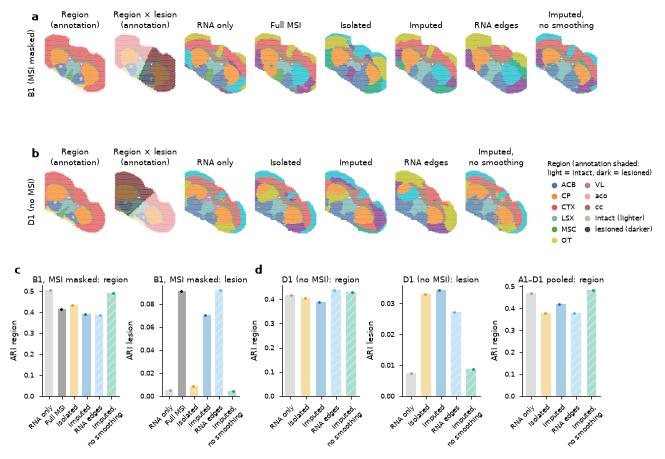

In [23]:
# Nature style: 183 mm double column, sans-serif 5-7 pt, thin lines, editable text in the pdf
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 6,
    "axes.titlesize": 6, "axes.labelsize": 6, "xtick.labelsize": 5, "ytick.labelsize": 5, "legend.fontsize": 5,
    "axes.linewidth": 0.5, "xtick.major.width": 0.5, "ytick.major.width": 0.5, "xtick.major.size": 2,
    "ytick.major.size": 2, "pdf.fonttype": 42, "svg.fonttype": "none",
})
REGION_COLORS = ["#4E79A7", "#F28E2B", "#E15759", "#76B7B2", "#59A14F", "#EDC948", "#B07AA1", "#FF9DA7", "#9C755F"]
EXTRA_COLORS = ["#17BECF", "#BCBD22", "#7F3C8D", "#11A579", "#E73F74", "#80BA5A", "#008695", "#CF1C90", "#A5AA99"]
CLUSTER_COLORS = ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02", "#a6761d", "#1f78b4",
                  "#666666", "#b2df8a", "#fb9a99", "#cab2d6", "#ffff99", "#b15928"]
METHOD_COLORS = {"RNA only": "#9e9e9e", "Full MSI": "#000000", "MSI masked, isolated": "#E69F00",
                 "MSI masked, imputed": "#0072B2", "Mosaic, isolated": "#E69F00", "Mosaic, imputed": "#0072B2",
                 "MSI masked, RNA edges": "#56B4E9", "Mosaic, RNA edges": "#56B4E9",
                 "MSI masked, imputed, no smoothing": "#009E73", "Mosaic, imputed, no smoothing": "#009E73"}
SHORT_NAMES = {"MSI masked, isolated": "Isolated", "MSI masked, imputed": "Imputed",
               "Mosaic, isolated": "Isolated", "Mosaic, imputed": "Imputed",
               "MSI masked, RNA edges": "RNA edges", "Mosaic, RNA edges": "RNA edges",
               "MSI masked, imputed, no smoothing": "Imputed,\nno smoothing",
               "Mosaic, imputed, no smoothing": "Imputed,\nno smoothing"}
CONTROLS = ("RNA edges", "no smoothing")  # control methods, hatched in the bar plots
show_controls = True  # also show the controls as maps
xy = pd.DataFrame(mdata.obsm["spatial"], index=mdata.obs_names, columns=["x", "y"])
regions = mdata.obs["RegionLoupe"].dropna().astype(str).sort_values().unique()
region_color = dict(zip(regions, REGION_COLORS))


def shade(color, lesioned_fraction):
    # 0 = all intact (lighter), 0.5 = region colour, 1 = all lesioned (darker)
    rgb = np.array(to_rgb(color))
    a = (lesioned_fraction - 0.5) * 2 * 0.45
    return to_hex(rgb * (1 - a) if a > 0 else rgb + (1 - rgb) * -a)


def annotation_colors(labels):
    # colour of every cluster: the region it overlaps most (no shading)
    spots = labels.index[known[labels.index].to_numpy()]
    df = pd.DataFrame({
        "cluster": labels[spots].to_numpy(),
        "region": mdata.obs.loc[spots, "RegionLoupe"].astype(str).to_numpy(),
        "lesioned": (mdata.obs.loc[spots, "lesion"].astype(str) == "lesioned").to_numpy(),
    })
    counts = pd.crosstab(df["cluster"], df["region"])
    region, size = counts.idxmax(axis=1), counts.max(axis=1)
    # the largest cluster of a region keeps the region colour, further clusters of that region get own colours
    colors, used, extra = {}, set(), itertools.cycle(EXTRA_COLORS)
    for c in size.sort_values(ascending=False).index:
        colors[c] = next(extra) if region[c] in used else region_color[region[c]]
        used.add(region[c])
    return colors


def spot_map(ax, spots, colors, title):
    ax.scatter(xy.loc[spots, "x"], xy.loc[spots, "y"], s=0.6, c=colors, linewidth=0, rasterized=True)
    ax.set_aspect(1)
    ax.invert_yaxis()
    ax.axis("off")
    ax.set_title(title, pad=2)


def map_methods(experiment):
    return [m for m in EXPERIMENTS[experiment][1] if show_controls or not m.endswith(CONTROLS)]


def map_row(fig, grid, section_name, experiment, panel, row_label):
    spots = mdata.obs_names[section == section_name]
    obs = mdata.obs.loc[spots]
    methods = map_methods(experiment)
    axes = [fig.add_subplot(grid[i]) for i in range(2 + len(methods))]
    regions_here = obs["RegionLoupe"].astype(str)
    lesioned_here = (obs["lesion"].astype(str) == "lesioned").astype(float)
    spot_map(axes[0], spots, [region_color.get(r, "#f0f0f0") for r in regions_here], "Region\n(annotation)")
    spot_map(axes[1], spots, [shade(region_color[r], l) if r in region_color else "#f0f0f0"
                              for r, l in zip(regions_here, lesioned_here)], "Region × lesion\n(annotation)")
    for ax, method in zip(axes[2:], methods):
        labels = exp_labels[experiment, method]
        colors = annotation_colors(labels)
        spot_map(ax, spots, [colors.get(l, "#bdbdbd") for l in labels[spots]], SHORT_NAMES.get(method, method))
    axes[0].text(-0.15, 1.12, panel, transform=axes[0].transAxes, fontsize=8, fontweight="bold", va="bottom")
    axes[0].text(-0.08, 0.5, row_label, transform=axes[0].transAxes, rotation=90, va="center", ha="right")
    return axes


def score_panel(ax, experiment, section_name, metric, title, panel=None):
    df = exp_scores[(exp_scores["experiment"] == experiment) & (exp_scores["section"] == section_name)]
    methods = list(EXPERIMENTS[experiment][1])
    rng = np.random.default_rng(0)
    for i, method in enumerate(methods):
        vals = df.loc[df["method"] == method, metric].to_numpy()
        ax.bar(i, vals.mean(), width=0.65, color=METHOD_COLORS[method], alpha=0.35, linewidth=0,
               hatch="////" if method.endswith(CONTROLS) else None, edgecolor="white")
        ax.scatter(i + rng.uniform(-0.15, 0.15, len(vals)), vals, s=4, color=METHOD_COLORS[method], linewidth=0, zorder=3)
    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels([SHORT_NAMES.get(m, m) for m in methods], rotation=45, ha="right", rotation_mode="anchor")
    ax.set_ylabel(metric)
    ax.set_title(title, pad=2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(bottom=min(0, df[metric].min() * 1.1))
    if panel:
        ax.text(-0.35, 1.08, panel, transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom")


mm = 1 / 25.4
fig = plt.figure(figsize=(183 * mm, 128 * mm))
outer = fig.add_gridspec(3, 1, height_ratios=[1, 1, 1.0], hspace=0.25)
b1 = masked_section.split("_")[1]
n_cols = max(2 + len(map_methods("masked")), 3 + len(map_methods("mosaic")))  # one free slot for the legend
map_row(fig, outer[0].subgridspec(1, n_cols, wspace=0.05), masked_section, "masked", "a", f"{b1} (MSI masked)")
map_row(fig, outer[1].subgridspec(1, n_cols, wspace=0.05), "V11L12-109_D1", "mosaic", "b", "D1 (no MSI)")

# legend in the last slot of row b
leg_ax = fig.add_subplot(outer[1].subgridspec(1, n_cols)[n_cols - 1])
leg_ax.axis("off")
leg_ax.legend(
    handles=[plt.Line2D([], [], marker="o", ls="", ms=3, color=region_color[r], label=r) for r in regions]
    + [plt.Line2D([], [], marker="o", ls="", ms=3, color=shade("#808080", f), label=l)
       for l, f in [("intact (lighter)", 0.0), ("lesioned (darker)", 1.0)]],
    loc="center left", frameon=False, ncol=2, handletextpad=0.1, columnspacing=0.6, title="Region (annotation shaded:\nlight = intact, dark = lesioned)",
    title_fontsize=5,
)

bottom = outer[2].subgridspec(1, 5, wspace=0.55)
score_panel(fig.add_subplot(bottom[0]), "masked", masked_section, "ARI region", f"{b1}, MSI masked: region", "c")
score_panel(fig.add_subplot(bottom[1]), "masked", masked_section, "ARI lesion", f"{b1}, MSI masked: lesion")
score_panel(fig.add_subplot(bottom[2]), "mosaic", "V11L12-109_D1", "ARI region", "D1 (no MSI): region", "d")
score_panel(fig.add_subplot(bottom[3]), "mosaic", "V11L12-109_D1", "ARI lesion", "D1 (no MSI): lesion")
score_panel(fig.add_subplot(bottom[4]), "mosaic", "all", "ARI region", "A1–D1 pooled: region")

fig.savefig(out_dir / "mosaic_imputation_figure.pdf", bbox_inches="tight", dpi=600)
fig.savefig(out_dir / "mosaic_imputation_figure.png", bbox_inches="tight", dpi=300)
plt.show()